# Megaline Plan Modernization
## Using Binary Classification ML to enhance adoption of updated pricing strategies 

## Case Study
Megaline, a cellular carrier, has implemented new cellular plans; however, a number of their users are still on legacy plans. Our business goal is to use existing customer data to analyze adoption behavior and recommend the modern cellular plan that best fits each legacy user based on learned behavioral patterns. The model will then be used to predict the most suitable plan for users who have not yet transitioned.

We have access to behavioral data from users who have already adopted one of the new plans, **Smart** or **Ultra**. Because the target column has only two possible values, this is a **binary classification** problem. Using this data, we aim to classify legacy users based on the plan that best aligns with their usage patterns. A minimum accuracy threshold of **0.75** has been established to ensure the model provides reliable recommendations.

Our accuracy will depend on several factors, including data granularity, data diversity, the correlation between feature relationships and the target feature, model fit, hyperparameter optimization, and the strength of the natural dichotomy between **Smart** and **Ultra** users. We can optimize and refine a model to the best of our abilities with the resources we have at our disposal, but even ML classification is probabilistic, not deterministic.

To safeguard against overfitting, we will try to maintain a conservative approach if possible, but will ultimately accept the model that results in the highest accuracy.

## Environment Setup

### Packages and Modules

In this study, we use standard data science libraries such as pandas and NumPy, along with scikit-learn for machine learning. These tools are widely used in Jupyter Notebook workflows and provide efficient support for data handling, model training, and evaluation. We will import classification models appropriate for this task, along with evaluation metrics used to compare their performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Raw Dataset (.CSV)

Our dataset, `users_behavior.csv`, is located at `datasets/users_behavior.csv`. We will import it with pandas and assign the resulting DataFrame to the variable df. Since this project uses a single prepared dataset, this step is straightforward.

In [2]:
df = pd.read_csv('datasets/users_behavior.csv')

### DataFrame
Now that the dataset has been imported, we can briefly inspect its structure and confirm that it is ready for modeling. We were informed that the data has already been cleaned and prepared. Even so, it is still important to verify the dataset structure, data types, and overall condition before moving into model development.

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB
None


It looks like we have **3,214** rows with **0** null values. Our assessment is that this dataset may be reasonably representative of the underlying population — but not without some concern. As a rule of thumb, 1,000-10,000 observed trials are often found to be adequate; however, this can be contextual and may not apply to all experiments. If we define a sample $S$ and population $P$, then $S \subseteq P$. If the sample is sufficiently random and representative, the average of observed outcomes will stabilize and approximate the true expected probability.

In Probability and Statistics, the Law of Large Numbers states that as sample size increases, the average of observed outcomes approaches the true underlying population expectation. This is commonly illustrated by the coin flip experiment — as the number of trials increases, the observed proportion of heads converges toward the true probability. In other words, as sample size grows, repeated trial results better approximate the true probability $P(E)$ of an event in the population. **However, increasing sample size alone does not guarantee accuracy if the sample is biased or not representative of the broader population.** We cannot compare our sample set to the full population, and cannot reasonably assume that this is a perfectly collected sample of all Megaline users. These observations must contextualize our final results.

In regards to data completion, the absence of null values signifies that we will not need to drop rows or extrapolate values. **Out of our 3,214 rows, we can retain all rows for training and testing.** This helps us avoid further bias and maintain our approximation based on the sample set's original quality (whatever that may be).

To clearly confirm our null count observation:

In [4]:
print(df.isna().values.sum())

0


To check for duplicate rows:

In [5]:
print(df.duplicated().sum())

0


To understand the structure and function of each column, we'll create a reference table for our data:

| Column        | Description                                 | Data Type |
|---------------|---------------------------------------------|-----------|
| calls         | number of calls made                        | float64   |
| minutes       | sum of call durations (minutes)             | float64   |
| messages      | count of text messages sent                 | float64   |
| mb_used       | Megabytes of data used                      | float64   |
| **is_ultra**  | if user joined ultra (boolean as binary int)| int64     |

It looks like our column names are concise, descriptive, and intuitive. `float64` ensures adequate precision for modeling while providing compatibility with ML packages, and our binary outcome is represented as a discrete integer. This data looks to be well-prepped. And because all feature columns are numerical, **we are not required to convert any column to a categorical column**. While our target variable is of categorical nature, the model type we choose (classification) will result in the prediction of a discrete target value; however, the feature columns it uses to predict this outcome will need to be treated as numerical, continuous values. And given that all features are treated as continuous (even if they are of discrete nature), the model will learn thresholds within a continuous spectrum to find optimal inflection points to classify a discrete outcome.

We can also preview several rows to become familiar with the structure of the dataset:

In [6]:
print(df.head(5))

   calls  minutes  messages   mb_used  is_ultra
0   40.0   311.90      83.0  19915.42         0
1   85.0   516.75      56.0  22696.96         0
2   77.0   467.66      86.0  21060.45         0
3  106.0   745.53      81.0   8437.39         1
4   66.0   418.74       1.0  14502.75         0


## Feature Columns and Target Variable
We know that our `features` are every column but `is_ultra`, and our target column, inversely, is `is_ultra`. We will assign our `features` and `target` variables so they can be used to train, validate, and test model candidates.

### `target`
Since our goal is to predict whether a user belongs to the **Ultra** or **Smart** plan, we will assign the `is_ultra` column to the `target` variable. The value is a binary representation of whether or not they are an **Ultra** user. A value of 1 means they are an **Ultra** user, and a value of 0 means they aren't.

In [7]:
target = df['is_ultra']
print(target.head(5))

0    0
1    0
2    0
3    1
4    0
Name: is_ultra, dtype: int64


### `features`

The remaining columns -- `calls`, `minutes`, `messages`, and `mb_used` -- will be assigned to the `features` variable. These values will be used by the model to identify relationships that model the probabilistic behavior of each user group. 

In [8]:
features = df.drop(['is_ultra'], axis=1)
print(features.head(5))

   calls  minutes  messages   mb_used
0   40.0   311.90      83.0  19915.42
1   85.0   516.75      56.0  22696.96
2   77.0   467.66      86.0  21060.45
3  106.0   745.53      81.0   8437.39
4   66.0   418.74       1.0  14502.75


## Training, Validation, and Test Sets
Next, we'll create our training, validation, and test sets. This will allow us to use separate groups for training the model, optimizing its performance, and final evaluation.

### train_test_split()

To train and evaluate our models, we will split our data into three groups: a **training set**, a **validation set**, and a **test set**.

* The **training set** will be used to train each model
* The **validation set** will be used to compare benchmark performance and perform hyperparameter tuning
* The **test set** will be reserved for final evaluation

Our first data split will have:

* **60% training data**
* **40% validation/test data**

In [9]:
features_train, features_temp, target_train, target_temp = train_test_split(
    features, 
    target, 
    test_size=0.4, 
    random_state=42
)

Then, we split the validation/test data in half, resulting in:

* **50% validation data**
* **50% test data**

In [10]:
features_valid, features_test, target_valid, target_test = train_test_split(
    features_temp,
    target_temp,
    test_size=0.5,
    random_state=42
)

This gives us a final **3-way split of 60/20/20**, which is appropriate for training, model selection, and final testing.

To keep results reproducible in runtime, we used `random_state=42` to enforce pseudo-randomness. 

### Empirical Preservation in the Experimental Group
While there's not much we can do to enforce entropy in the data we were *given*, we *can* take apt measures to ensure our *sampling of that data* minimizes distribution bias. This prevents additional sampling bias from contaminating our study, enabling us to maximize our confidence given the circumstances.

First, we can observe the distribution of **Smart** to **Ultra** users in our entire dataset.

In [11]:
print("Overall class distribution:")
print(df['is_ultra'].value_counts(normalize=True) * 100)

Overall class distribution:
0    69.352831
1    30.647169
Name: is_ultra, dtype: float64


We find that there is roughly a 70:30 split in favor of **Smart** users.

Next, we can compare that distribution to the training, validation, and testing sets:

In [12]:
print("\nTraining set distribution:")
print(target_train.value_counts(normalize=True) * 100)

print("\nValidation set distribution:")
print(target_valid.value_counts(normalize=True) * 100)

print("\nTest set distribution:")
print(target_test.value_counts(normalize=True) * 100)


Training set distribution:
0    69.242739
1    30.757261
Name: is_ultra, dtype: float64

Validation set distribution:
0    69.362364
1    30.637636
Name: is_ultra, dtype: float64

Test set distribution:
0    69.673406
1    30.326594
Name: is_ultra, dtype: float64


We find that the roughly 70/30 split is preserved across all subsets and their supersets. 

This 70/30 split provides another key insight:

**Ultra users, our target market, only constitute about 30% of our users in this distribution.** While it's nice to see that we have a considerable portion of each demographic, this context will frame our evaluation of each model metric. 

### **Bonus**: Unit Testing train_test_split()

Machine Learning models often need to run through proven, auditable scenarios and benchmarks during and after production, which makes them a perfect pair with unit testing. For process validation, we can test critical points during development where unintended errors could cause massive miscalculations in predictions. In this case, having index drift could be fatal, especially for non-temporal data, where the result wouldn't just be timestamp delay -- it would be complete user identity misinterpretations. In just a few lines, we can ensure the alignment of our indices to prevent a colloquial "Garbage In, Garbage Out" result -- especially when we're watching Pricing Strategy predictions manifest, and Sales & Marketing may run targeted promotional campaigns based on our decisions.

We'll use these keywords and functions to quickly test our index alignments:

> `assert` **boolean**, **string**: using the `assert` keyword, you can assert any boolean value to be `True`. You provide a string to raise as the error message in an AssertionError in the case that it is `False`.

> `pandas.DataFrame.equals()`: the `DataFrame.equals()` function is best used to evaluate the equality between DataFrame and Series objects, as it is specifically designed by pandas to compare their data types. This will produce our `True` or `False` value.

We use the `assert` operator with an error string to raise in the event of a `False` boolean evaluation.

In [13]:
assert features_train.index.equals(target_train.index), "[Training Data Error] features_train & target_train indices are not aligned!"
assert features_test.index.equals(target_test.index), "[Test Data Error] features_test & target_test indices are not aligned!"
assert features_valid.index.equals(target_valid.index), "[Validation Data Error] features_valid & target_valid indices are not aligned!"

In our case, no new is good news. No `AttributeError` raised means that our indices equality checks returned `True`, confirming the alignment of all indices.

## Exploratory Data Analysis
With our data split performed and split quality inspected, our data can now be used with various models. But before we build models, we will analyze the behavioral patterns of our users based on our feature data. This helps us make informed decisions on model choice by understanding what features should lead to proper classification, and gives us a general expectation for model behavior. Gaining insights and making informed decisions based on scientific observations is a better approach than blindly chasing performance metrics.

### Empirical Distribution of Data
First, we'll use `df.describe()` to observe the empirical distribution of data.

In [14]:
df.describe()

,calls,minutes,messages,mb_used,is_ultra
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,63.038892,438.208787,38.281269,17207.673836,0.306472
std,33.236368,234.569872,36.148326,7570.968246,0.461100
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.000000,274.575000,9.000000,12491.902500,0.000000
50%,62.000000,430.600000,30.000000,16943.235000,0.000000
75%,82.000000,571.927500,57.000000,21424.700000,1.000000
max,244.000000,1632.060000,224.000000,49745.730000,1.000000


**First, we observe again our 70-30 split of data in favor of Smart users.** Importantly, this does frame accuracy -- our most desired performance metric -- with a bit of nuance. A model that is 70% accurate can predict that every user is a Smart user. However, that model has shown no fundamental understanding of our minority group of Ultra users. This is an intriguing classification case because at its heart, there's one question -- when two binary outcomes are of equal favor and overall accuracy is paramount, how do you develop a prediction model that promises to scale, when the dataset is limited and distribution is inherently biased? This is when precision and recall become points of interest. It allows us to understand how often our model mistakenly predicts Ultra users, and how many Ultra users it correctly identifies. In this case, precision and recall become more than efficiency and completion dials. Instead, they become indicators of minority group advocation when that group is predisposed to bias by rarity. And in this case, the minority group are presumably our highest-paying users. Nevertheless, the ultimate goal is accuracy, as legacy migration is our end goal... But to promote accuracy, our model needs to understand the behavior of both groups.

**`mb_used`, our data consumption feature, high extremely high range. And it's measured in megabytes.** While other columns range from 0 to a matter of hundreds or thousands, data consumption -- presumably our prime indicator of plan choice -- measures from 0 to about 50,000. As opposed to having a standard deviation in dozens or hundreds, it has a standard deviation of about 7,500. Naturally, data usage patterns are on a completely different scale than other metrics. While messages and calls are discrete quantities and could be adapted to the same relative grid, data usage is represented in megabytes. Call minutes are represented in minutes as well, a measurement of time. Because of this, we wouldn't expect a logistic regression model to easily adapt a regression line or sigmoid curve to these values.

**We have a minimum of 0 for all feature columns.** We have some users who don't consume data at all. Could these be forgotten lines? Users who truly don't use their phone much? Valuable enterprise customers who have reserve lines for future employees, and don't toll the network? This obfuscates active customer behavior, but it still represents paying customer behavior. And ultimately, it represents customer behavior overall. We might find that the only users who use no traffic are those enterprise, B2B phone lines who pay Ultra plans for future employees. The model could determine that. And this is where a classification model would shine -- meanwhile, it may distort reality for a regression model.

**Next, we will generate boxplots of each feature for each user demographic.**

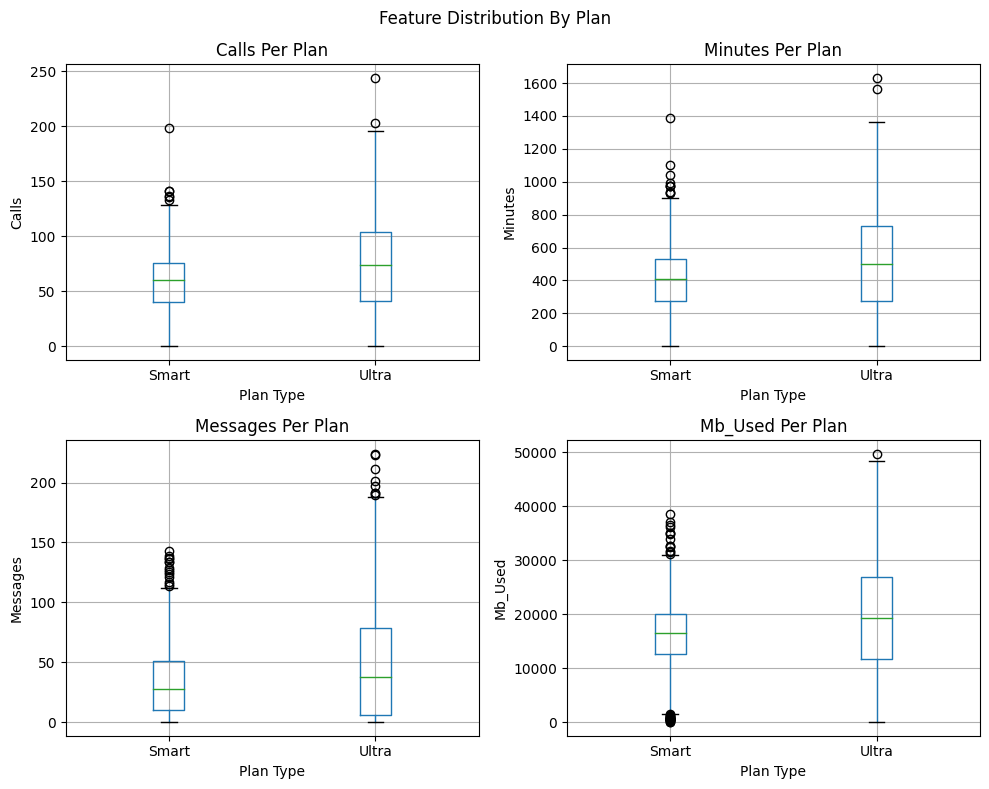

In [15]:
columns = df.drop(columns=['is_ultra']).columns.tolist()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

count = 0
for col in columns:
    df.boxplot(by='is_ultra', column=col, ax=axes[count])
    axes[count].set_title(f'{col.title()} Per Plan')
    axes[count].set_xlabel(f'Plan Type')
    axes[count].set_ylabel(col.title())
    axes[count].set_xticklabels(['Smart', 'Ultra'])
    count+=1
    
plt.suptitle("Feature Distribution By Plan")
plt.tight_layout()
plt.show()

**Based on our data, we can see that Ultra users consistently have a higher median in consumption -- but also higher variance.** Across all features, the median consumption for Ultra users is higher than that of Smart users. Meanwhile, Ultra users also have a wider distribution in both IQR width and whisker length, while Smart users are tighter in distribution. This shows that our Ultra users do consume more as a collective, but they're much less predictable. This adds even more nuance to our observations made about this case. Not only are Ultra users a higher-paying minority in a classification situation where no group should be favored, but their behavior is inherently less predictable.

**While Ultra users have higher variance, there's clear overlap between Smart and Ultra users.** To add to the complexity of predicting Ultra users, the overlap between Smart and Ultra users will likely make this group exceptionally hard to distinguish. Accuracy gains may be difficult to achieve, and we should expect some false predictions in this territory, especially given the limited dataset (and resulting smaller subsets). This is where precision and recall will allow us to gauge the model's actual understanding of the Ultra user community, a dichotomal requirement that will ultimately contextualize its final accuracy score.

**Both users have outliers, but Smart users have a higher quantity of outliers.** And while they do have more outliers, they also outratio our Ultra users in the 70/30 split. Our Smart group is roughly 233% the volume of our Ultra group (or 133% more than Ultra user volume). The sheer number of Smart users is likely partially responsible for the increase in outliers -- not behavior model alone. Smart users *do* have an elevated Q1 lower whisker boundary, suggesting that they may be less likely to consume no data. But we do have an outlier presence under that boundary, and it's dense. As far as data consumption goes, it suggests Ultra users may be more likely to consume no data, as we previously brushed on.

**Nevertheless, we see a trend across consumption patterns. Ultra users have a consistently elevated median, a wider IQR box, and longer whiskers, but there's significant overlap.** The consumption patterns are quite similar, though the Ultra distribution's central tendency is bit higher. They have a wider range, and therefore can be more variable in nature. Many of them fall within the neighborhood of Smart users in terms of consumption, but even with a smaller dataset, the threshold for normal consumption is much higher.


**Next, we'll observe the relative median deltas for each feature column, as it changes from Smart to Ultra users.**

First, we'll use the `groupby()` function to group our DataFrame by our target column. Then, we'll take the median of our four feature columns.

In [16]:
medians = df.groupby('is_ultra')[['calls','minutes','messages','mb_used']].median()
medians

,calls,minutes,messages,mb_used
is_ultra,,,,
0,60.0,410.56,28.0,16506.93
1,74.0,502.55,38.0,19308.01


Next, we'll create a DataFrame using a dictionary, where:

- **key**: each plan name
- **value**: the respective feature medians, pulled from the rows above using `.loc[index]`

In [17]:
median_table = pd.DataFrame({
    'smart': medians.loc[0],
    'ultra': medians.loc[1]
})
median_table

,smart,ultra
calls,60.00,74.00
minutes,410.56,502.55
messages,28.00,38.00
mb_used,16506.93,19308.01


Finally, we'll create two new columns for this DataFrame, where:

- **delta**: `ultra` column - `smart` column
- **delta%**: (`delta` column / `smart` column) * 100

We will then sort the DataFrame by the `delta%` column (descending) to sort them by relative increase.

In [18]:
median_table['delta'] = median_table['ultra'] - median_table['smart']
median_table['delta%'] = (median_table['delta'] / median_table['smart']) * 100
median_table.sort_values(by='delta%', ascending=False)

,smart,ultra,delta,delta%
messages,28.00,38.00,10.00,35.714286
calls,60.00,74.00,14.00,23.333333
minutes,410.56,502.55,91.99,22.405982
mb_used,16506.93,19308.01,2801.08,16.969115


The table above shows:
- **smart, ultra**: the median consumption for each feature column as it relates to each plan
- **delta**: the increase in consumption from Smart to Ultra
- **delta%**: the delta converted to a percentage (i.e., the percentage more that Ultra users consume over Smart users)

**As you can see, messaging stands to have the highest proportional increase from Smart to Ultra users.** Ultra users send and receive nearly 136% the number of messages that Smart do.

**The number of calls and aggregate call duration had close percentage increases, suggesting similar behavior.** By about 22-23%, call quantity and duration increased from Smart to Ultra. This shows that behavior is somewhat similar, but the number of calls rose slightly more than the duration. This suggests that Ultra users may be more likely to engage in more frequent, but potentially shorter calls. Without directly calculating call duration trends across both groups, this cannot be asserted.

**Data consumption had the lowest relative increase.** While the Ultra user data consumption boxplot showed a very wide spread, data consumption actually had the lowest proportional increase across all four features. 

## Baseline Model Comparison
Now that our data has been prepared, we need to test the performance of different model baselines. Because this process will be repeated several times, we'll make some functions to organize the code. This helps with organization, reduces repetitive code, and lets us focus on model performance instead of large blocks of repeated code.

### Setup: `evaluate_model()` (with helper functions)
Thanks to scikit-learn's well-structured classes, the process of training models, predicting outcomes, and evaluating benchmarks is so structured that basically all of our ML model code -- aside from model instantiation -- can be reused. To organize code, we'll write a function to leverage code reusability and draw well-earned attention to the model constructor, as this is where the magic happens.

Our `evaluate_model()` function will:
- train a model using `features_train` and `target_train`
- generate `predictions` using `features_valid`
- compare those predictions against `target_valid`
- return the resulting benchmark metrics in a structured format

We also use helper functions to keep this workflow organized:
- `get_scores()` calculates the benchmark metrics
- `get_string_results()` formats model details and results into a dictionary
- `validate_strings()` checks that the stored metric values match the calculated ones
- `print_model_name()` extracts a cleaner model name for display

This organization allows us to better focus on the business logic. Our functions aredescriptive enough to read the operational flow, and aren't cluttered with string-related noise. This will also allow us to represent the ML work with more brevity.

In [19]:
# business logic for training ML models

def evaluate_model(model, features_train, target_train, features_valid, target_valid):
    model.fit(features_train, target_train)
    predictions = model.predict(features_valid)
    accuracy, precision, recall, f1 = get_scores(target_valid, predictions)
    string_results = get_string_results(model, accuracy, precision, recall, f1)
    validate_strings(accuracy, precision, recall, f1, string_results)
    df_results = pd.DataFrame([string_results])
    return accuracy, precision, recall, f1, df_results

def get_scores(target_eval, predictions):
    accuracy = accuracy_score(target_eval, predictions)
    precision = precision_score(target_eval, predictions)
    recall = recall_score(target_eval, predictions)
    f1 = f1_score(target_eval, predictions)
    return accuracy, precision, recall, f1

# unit testing to validate string processing results against benchmarks

def validate_strings(accuracy, precision, recall, f1, string_results):
    assert (round(accuracy, 4) == string_results['accuracy']), "STRING PARSING ERROR: " + str(round(accuracy, 4)) + " is not " + str(string_results['accuracy'])
    assert (round(precision, 4) == string_results['precision']), "STRING PARSING ERROR: " + str(round(precision, 4)) + " is not " + str(string_results['precision'])
    assert (round(recall, 4) == string_results['recall']), "STRING PARSING ERROR: " + str(round(recall, 4)) + " is not " + str(string_results['recall'])
    assert (round(f1, 4) == string_results['f1']), "STRING PARSING ERROR: " + str(round(f1, 4)) + " is not " + str(string_results['f1'])
    
# string and printing-related activities: no business logic down here!

def get_string_results(model, accuracy, precision, recall, f1):
    string_results = {'model_name': print_model_name(str(model))}
    string_results['accuracy'] = round(accuracy, 4)
    string_results['precision'] = round(precision, 4)
    string_results['recall'] = round(recall, 4)
    string_results['f1'] = round(f1, 4)
    for key, value in model.get_params().items():
        string_results[key] = value
    return string_results

def print_model_name(model_str):
    model_str = model_str.replace(")", "")
    return model_str.split("(", 2)[0]

### Machine Learning Model Experimentation
Next, we will select the model that best fits our project needs. Our goal is to experiment with different ML models to find the generally best performing model. We will use a combination of domain knowledge, applied concepts, and trial and error to find the optimal model and hyperparameter configuration. We may end up with a few possible types -- this is not only to be expected, but is optimal as it gives us options and even insights into the nature of our feature relationships. 

Because our target variable is a binary classification (`is_ultra` user or not), we will use a **classification** model. A **classification** model is used to, well, result in the **classification** of data. The prediction model treats feature columns as a weighted, probabilistic determinator towards a potential discrete, categorical outcome in the target value column. It assesses the possible outcomes (e.g., `is_ultra` or not), weighs the factors and relationships (probabilities) that most commonly yield the outcome of each possibility, and predicts target values based on a trial's feature values, influenced by these probabilities. 

This is in comparison to something like a linear **regression** model that would treat feature columns as algebraic independent variables against the target dependent variable, and attempt to construct the line of best fit for a scalar output formula to predict values on a continuous y-axis. Effectively, the difference is that a classification model results in categorical predictions, while regression models result in an often continuous quantitative value (e.g., predicting the temperature tomorrow, or the cost of a car based on features). 

**This tremendously helps us in choosing a model, as it rules out**: 

> - LinearRegression
> - DecisionTreeRegressor
> - RandomForestRegressor

**Instead, we will favor model candidates that result in the classification of data, such as**:

> - LogisticRegression
> - DecisionTreeClassifier
> - RandomForestClassifier

It should be noted that **LogisticRegression** is not a regression model in the sense of the other regression models. It uses linear algebra techniques to map a sigmoid (S-shaped) curve that is used in assigning relative probability weights (between 0 and 1) to input (feature) variables, though the process of **LogisticRegression** ultimately results in the binary classification of predicted values based on these relative feature probabilities.

#### LogisticRegression
Since we're on the topic, let's start with **LogisticRegression**.
This is where our code organization pays off -- we can see the constructor, parameters, cleanly validate `evaluate_model()` usage, and observe the results with no real noise.

We'll use the parameter of `random_state`=`42` to set the pseudo-RNG seed to 42, giving us a pseudo-deterministic random state that ensures consistent results across repeated runtime sequences.

In [20]:
model = LogisticRegression(
    random_state=42
)
results_dict = evaluate_model(model, features_train, target_train, features_valid, target_valid)[-1]
results_dict

/.venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:763: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model_name,accuracy,precision,recall,f1,C,class_weight,dual,fit_intercept,intercept_scaling,l1_ratio,max_iter,multi_class,n_jobs,penalty,random_state,solver,tol,verbose,warm_start
0,LogisticRegression,0.7403,0.7778,0.2132,0.3347,1.0,None,False,True,1,None,100,auto,None,l2,42,lbfgs,0.0001,0,False


We can see that our accuracy rating is **0.7403**, putting us within the ballpark of our target value of accuracy = 0.75. And while accuracy is important, it's only one piece of the puzzle.

Our precision is **0.7778**, mean that when it predicts an Ultra user, it is often correct in doing so. 

However, our recall score is **0.2132**, meaning that it found a low percentage of the actual Ultra users. This imbalance results in a low F1 score of **0.3347**, indicating poor balance between precision and recall.

In conclusion, while this model may approach our minimum requirement for accuracy, its low recall (and therefore F1 score) makes it a poor candidate for production as it heavily unfavors Ultra members in prediction.

#### DecisionTreeClassifier
Next, we can move on to a **DecisionTreeClassifier**. Instead of algebraic sigmoid functions weighing feature importances, this model produces decision trees with optimized routes that result in algorithmic decision making based on probable inflection points and thresholds. This is more in line with what we'd expect -- something like "if `messages` > 201.28, choose child_node a...".

However, model behavior alone won't get us there -- the **DecisionTreeClassifier**, and similar models, can be prone to the overfitting problem we discussed earlier. We have 4 feature columns (`calls`, `messages`, `mb_used`, and `minutes`), but feature columns can be evaluated multiple times during the process to result in better predictive modeling. We'll allow `max_depth` = 6 to encourage some afterthought without letting our model spiral. If we can get within range, hyperparameter tuning will help us dial in on the right figures later.

For `min_samples_split`, we will require 10 people to establish a trend to split, and 5 to produce an outcome leaf. As we said earlier, we can fine-tune hyperparameters, but also want to leave room to observe non-binary trends in our outcomes. `max_features`=`sqrt` prevents reliance on fewer features, which is a risk in our model with only 4 columns.


In [21]:
model = DecisionTreeClassifier(
    max_depth=6,                
    min_samples_split=10,                
    min_samples_leaf=5,         
    max_features='sqrt',        
    random_state=42
)
evaluate_model(model, features_train, target_train, features_valid, target_valid)[-1]

,model_name,accuracy,precision,recall,f1,ccp_alpha,class_weight,criterion,max_depth,max_features,max_leaf_nodes,min_impurity_decrease,min_impurity_split,min_samples_leaf,min_samples_split,min_weight_fraction_leaf,random_state,splitter
0,DecisionTreeClassifier,0.776,0.7573,0.3959,0.52,0.0,None,gini,6,sqrt,None,0.0,None,5,10,0.0,42,best


The **DecisionTreeClassifier** performed considerably better than the **LogisticRegression** model. In validation, its accuracy crossed over our minimum threshold with a score of **0.776**. Precision declined slightly (**0.7573**), but the increase in recall produced a score of **0.3959**, increasing the quantity of Ultra users identified. As a result, our balance between precision and recall is represented in the F1 score, which rose to **0.52**. This showcases the structural advantage that tree models have when applied to algorithmic binary prediction scenarios. Not only did overall accuracy raise, but the results demonstrate that it is more adaptable to understanding the behavior behind both groups.

#### RandomForestClassifier
Because **DecisionTreeClassifier** showed significant improvements over **LogisticRegression**, it is only natural that we try **RandomForestClassifier** as well. 

**RandomForestClassifier** is similar to **DecisionTreeClassifier** in the sense that it uses Tree data structures to classify data. What sets this model apart is that it uses an ensemble orchestration method to weigh the inputs of multiple decision trees to predict a target value. This added dimensionality can reduce the overfitting symptom that 1-dimensional tree models are known to produce. However, added complexity can overengineer the decision-making process, and the process can mystify interpretability (compared to a classical decision tree, or an algebraic slope formula).

Here, we'll add the `n_estimators` hyperparameter and set its value to **200**. This will allow 200 decision trees to weigh in on the final outcome of a prediction. In this attempt, we will try to leverage sophistication, increasing the depth and reducing the number of users required to establish a trend and produce a leaf. 

In [22]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42
)
evaluate_model(model, features_train, target_train, features_valid, target_valid)[-1]

,model_name,accuracy,precision,recall,f1,bootstrap,ccp_alpha,class_weight,criterion,max_depth,...,min_impurity_split,min_samples_leaf,min_samples_split,min_weight_fraction_leaf,n_estimators,n_jobs,oob_score,random_state,verbose,warm_start
0,RandomForestClassifier,0.8118,0.7969,0.5178,0.6277,True,0.0,None,gini,10,...,None,2,5,0.0,200,None,False,42,0,False


Compared to both previous models, **RandomForestClassifier** has resulted in the highest scores. Not only did accuracy increase to **0.8118**, but precision rose to **0.7969**, indicating fewer cases of identifying Smart users as Ultra users. In terms of business implications, this implies that targeted campaigns towards Ultra users could be ran with more confidence as this model is the least likely to show an Ultra campaign to a Smart user. In terms of Ultra user exposure, a recall score of **0.5178** suggests that it is now identifying more than half of all Ultra users in trials. With these gains in recall, our F1 score has increased to a value of **0.6277**. While this model increased in all areas, its increase in F1 showcases its adaptability, balance, and promise for scale. 

Higher performance from **RandomForestClassifier** over a 1-dimensional tree model suggests that user behavior is more complex and contextual than what a single decision tree can model. Modeling complex relationships by overextending **DecisionTreeClassifiers** can result in overfitting, but using ensemble models can maintain structure while still applying contextual evaluation, due to its use of multiple trees with different perspectives. 

## Hyperparameter Tuning
As we've seen, selecting the right model makes a considerable difference. Like optimizing data structures, choosing the right model is fundamental to performance and efficiency. However, this is only part of the story. With **hyperparameter tuning**, one can optimize model configuration based on quantitative performance feedback.

### Hyperparameter Tuning - Conservative Approach
In the Technical Foreword, we discussed possibly favoring simplicity if quantitative benchmarks are not a factor. While **RandomForestClassifier** performed the best in initial evaluation, we will begin with the **DecisionTreeClassifier** based on its simplicity, auditability, and interpretability. If an optimized 1-dimensional model results in comparable success, it may be a solid candidate for production. 

Ultimately, with both models performing comparably well in evaluation, the best way to determine the strongest candidate would be to test both models. Given our conservative feature set and relatively low sample size, we have the opportunity to run a fairly cohesive **Grid Search** for both models using nested for-loops.

#### Step 1: Define the Parameter Grid

We can start out by defining constraints by providing a dictionary, where the key is the hyperparameter name, and the value is a list of possible values. Most of our list values will be integers (as the hyperparameters require), and some of them will be strings (such as `max_features`).

For resource conservation, we won't tax TripleTen's containers with variance in `max_features` or `random_state`. We'll increase the values within an approximate range so that our tuning process dials in the sweet spots.

In [23]:

results = []
param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': ['sqrt'],
    'random_state': [42]
}


#### Step 2: Systematic Testing

Here, we simply nest for-loops to iterate through each list in a nested fashion. To ensure our logic is correct, we can print the value at the index of each iterator's position. Since we don't have any added combinations with a fixed `max_features` and `random_state`, we don't need to add complexity by looping over these values. 

As you can see, we can test our output by simply printing the typecasted string values, then concatenating with commas to make it legible. This ensures we're looping correctly and obtaining the values correctly.

In [24]:
count = 15
for i in param_grid['max_depth']:
    for j in param_grid['min_samples_split']:
        for k in param_grid['min_samples_leaf']:
            if (count != 0):
                print(str(i) + ", " + str(j) + ", " + str(k) + ", " + str(param_grid['max_features'][0]) + ", " + str(param_grid['random_state'][0]))
                count-= 1
print("...")

3, 2, 1, sqrt, 42
3, 2, 2, sqrt, 42
3, 2, 5, sqrt, 42
3, 2, 10, sqrt, 42
3, 5, 1, sqrt, 42
3, 5, 2, sqrt, 42
3, 5, 5, sqrt, 42
3, 5, 10, sqrt, 42
3, 10, 1, sqrt, 42
3, 10, 2, sqrt, 42
3, 10, 5, sqrt, 42
3, 10, 10, sqrt, 42
3, 20, 1, sqrt, 42
3, 20, 2, sqrt, 42
3, 20, 5, sqrt, 42
...


This shows us a brief visualization of the loop, allowing us to confirm that the logic is following our intent. This confirms that our `Grid Search` is traversing correctly so that the entire hyperparameter space is evaluated.

Finally, it's just a matter of:
- instantiating the model using the constructor with the desired variable hyperparameters
- plugging in the variables
- calling the functions we made earlier to train, validate, and benchmark each iteration's performance
- and finally, inserting our identifying variables and the benchmark results to a dictionary, which is then added to our `results` list.

In [25]:
for i in param_grid['max_depth']:
    for j in param_grid['min_samples_split']:
        for k in param_grid['min_samples_leaf']:
            # print(str(i) + ", " + str(j) + ", " + str(k) + ", " + str(param_grid['max_features'][0]) + ", " + str(param_grid['random_state'][0]))
            # Simply plug in our values in the DecisionTreeClassifier constructor. 
            # Again, we'll reference our fixed columns using a static reference to the list's index 0.


            model = DecisionTreeClassifier(max_depth=i, 
                                           min_samples_split=j, 
                                           min_samples_leaf=k, 
                                           max_features=param_grid['max_features'][0], 
                                           random_state=param_grid['random_state'][0]
                                          )


            accuracy, precision, recall, f1, string_results = evaluate_model(model, features_train, target_train, features_valid, target_valid)
            # Append the results to the list. We'll make a dictionary so we can reconstruct the KV pairs as columns in a DF.
            results.append({'max_depth': i, 
                       'min_samples_split': j, 
                       'min_samples_leaf': k, 
                       'max_features': param_grid['max_features'][0], 
                       'random_state': param_grid['random_state'][0],
                       'accuracy': accuracy, 
                       'precision': precision, 
                       'recall': recall, 
                       'f1': f1, 
                      })

#### Step 3: Interpreting Results

Now that we've tuned our hyperparameters, we can simply convert `results` -- a list of dictionaries -- into a DataFrame using the default constructor.

If we sort values `by=['accuracy', 'precision', 'recall', 'f1']`, and set all columns to descend, we'll prioritize them in that order. In our case, since we're trying to move as many users as we can from a legacy plan to a modern plan, we prioritize accuracy to ensure highest overall correctness. Precision, recall, and F1 are evaluated as secondary tie-breakers.

In [26]:
param_df = pd.DataFrame(results)
sorted_df = param_df.sort_values(
    by=['accuracy', 'precision', 'recall', 'f1'], 
    ascending=[False, False, False, False]
)
best_tree = sorted_df.head(10)  # Show top 10 results
best_tree

,max_depth,min_samples_split,min_samples_leaf,max_features,random_state,accuracy,precision,recall,f1
80,8,2,1,sqrt,42,0.800933,0.767442,0.502538,0.607362
126,10,20,5,sqrt,42,0.800933,0.767442,0.502538,0.607362
109,9,20,2,sqrt,42,0.796267,0.766129,0.482234,0.591900
48,6,2,1,sqrt,42,0.796267,0.757812,0.492386,0.596923
100,9,5,1,sqrt,42,0.796267,0.742647,0.512690,0.606607
84,8,5,1,sqrt,42,0.793157,0.758065,0.477157,0.585670
85,8,5,2,sqrt,42,0.793157,0.758065,0.477157,0.585670
49,6,2,2,sqrt,42,0.793157,0.753968,0.482234,0.588235
72,7,10,1,sqrt,42,0.793157,0.753968,0.482234,0.588235
73,7,10,2,sqrt,42,0.793157,0.753968,0.482234,0.588235


**Here, we have the unique hyperparameter configuration of each tuning iteration, paired with the resulting benchmark scores.** Not only is this convenient for future use, but it gives us insight into the complexity of the decision-making process performed when the model yielded its highest scores. 

**Our top two models performed equally well with very different configurations.** The most notable differences in configuration lies in the minimum users required to create a new branch decision and the minimum users required to form a unique path. While one model requires 20 users to branch (high resistance to change), the other required merely 2 users (low resistance to change). The high-resistance model requires 5 users to form a unique path (broader grouping), and the low-resistance model allows each individual user to form their own unique path (niche profiles). While one approach allows aggressive branching and individual grouping, the other model is much more resistant to change and requires more clustered groups at the end of the tree. This suggests that even when given the liberty to create highly granular paths, the model does not show evidence of deviating from the learned relationships of the more conservative model. Ultimately, both a liberal and conservative model were able to identify the relationship equally well, indicating relatively low sensitivity to the hyperparameters applied.

**Our returns are diminishing.** Trailing iterations achieved relatively similar scores, many of them achieving identical values across many rows. Recall peaked in our 5th most accurate model, but our top two models shared the record for F1 score. The low variance in scores indicates an optimization plateau where further gains are unlikely to come from hyperparameter tuning.

In conclusion, we've seen that a liberally configured **DecisionTreeClassifier**, when given freedom in complexity, ultimately modeled the same relationships that a more conservative configuration did. But at the end of the day, neither achieved accuracy gains over **RandomForestClassifier**'s baseline accuracy score. While our clear winner is **RandomForestClassifier**, we are not finished yet; we will perform hyperparameter tuning on **RandomForestClassifier** to ensure we achieve the best possible model and configuration.

### Hyperparameter Tuning - Complex Approach
Tuning the **DecisionTreeClassifier** resulted in an accuracy score of **0.800933**, and diminishing returns were observed. Despite optimization, it fell short of our **RandomForestClassifier** baseline of **0.8118**. While we attempted the conservative approach of maintaining a 1-dimensional tree model, we've chosen **RandomForestClassifier** for its performance and production utility. Since our goal is to maximize accuracy, we will next tune the hyperparameters of **RandomForestClassifier** to yield the highest possible accuracy from our model of choice.

We will repeat the same hyperparameter tuning process above, but with more brevity in narration.

#### Step 1: Define the Hyperparameter Grid
We will create:
- `results`: an empty list to store result dictionaries
- `param_grid`: a dictionary of keys and lists, defining hyperparameters and their possible values

In [27]:
results = []
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt'],
    'random_state': [42]
}

#### Step 2: Systematic Testing
We use nested for-loops to loop through our `param_grid` hyperparameters that have multiple possible values. Single-value lists are referenced statically.

1. At the innermost level, we create a model using the variables for that loop iteration. 

2. Using our `evaluate_model()` function, we train and validate our model using our training and validation datasets.

3. From that function, the benchmark results are returned and stored to their respective variables.

4. With the benchmark results obtained, we store that iteration's hyperparameter configuration and benchmark results to a dictionary, and that dictionary is appended to our `results` list.

**Unique parameter values for that iteration**:
- `n_estimators`
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_features`
- `random_state`
  
**Benchmark scores for that iteration**:
- `accuracy`
- `precision`
- `recall`
- `f1`

In [28]:
for i in param_grid['n_estimators']:
    for j in param_grid['max_depth']:
        for k in param_grid['min_samples_split']:
            for l in param_grid['min_samples_leaf']:
                model = RandomForestClassifier(n_estimators=i, 
                                               max_depth=j, 
                                               min_samples_split=k,
                                               min_samples_leaf=l,
                                           max_features=param_grid['max_features'][0], 
                                           random_state=param_grid['random_state'][0]
                                              )

                accuracy, precision, recall, f1, string_results = evaluate_model(model, features_train, target_train, features_valid, target_valid)
                results.append({'n_estimators': i, 
                                'max_depth': j,
                                'min_samples_split': k, 
                                'min_samples_leaf': l, 
                                'max_features': param_grid['max_features'][0], 
                                'random_state': param_grid['random_state'][0],
                                'accuracy': accuracy, 
                                'precision': precision, 
                                'recall': recall, 
                                'f1': f1, 
                               })

Once the sequence is complete, our `results` will contain a list of dictionaries representing the unique hyperparameter configuration and the resulting benchmark results for each iteration spawned. With a list of dictionaries, we can use the `pd.DataFrame()` constructor to instantiate a DataFrame containing our results, where each row is a fingerprint of each iteration.

In [29]:
param_df = pd.DataFrame(results)

#### Step 3: Interpreting Results
Now that we've obtained the top scoring hyperparameter configurations for **RandomForestClassifier**, we can observe what values resulted in the highest performance for this model.

In [30]:
sorted_df = param_df.sort_values(
    by=['accuracy', 'precision', 'recall', 'f1'], 
    ascending=[False, False, False, False]
)
best_forest = sorted_df.head(10)  # Show top 10 results
best_forest
best_forest.loc[:, 'accuracy':'f1'].style.highlight_max(axis=0)

,accuracy,precision,recall,f1
60,0.816485,0.806202,0.527919,0.638037
58,0.813375,0.803150,0.517766,0.629630
100,0.813375,0.769231,0.558376,0.647059
61,0.811820,0.801587,0.512690,0.625387
91,0.811820,0.801587,0.512690,0.625387
92,0.811820,0.796875,0.517766,0.627692
94,0.811820,0.796875,0.517766,0.627692
95,0.811820,0.796875,0.517766,0.627692
96,0.811820,0.796875,0.517766,0.627692
98,0.811820,0.796875,0.517766,0.627692


**The tuned RandomForestClassifier beat its baseline 0.8118 accuracy score, achieving a max of 0.8165**. This model saw marginal gains in accuracy, but gains in accuracy nonetheless. In fact, we can see that 3rd through 10th place had the score that our baseline model had. This shows that while our accuracy did increase -- our primary objective -- the gains in accuracy were in fact minimal. Nevertheless, it's still more accurate than baseline, and even more accurate than our best **DecisionTreeClassifier** iteration. While accuracy gains were relatively minimal, much of our gains will come from other metrics that contribute to our model's value.

**It also topped its baseline precision, raising its score from 0.7969 to 0.8062.**	Similar to accuracy, we gained slight increases in terms of precision. Our original **RandomForestClassifier**'s precision value is that of the models in 5th place through 10th place. Nevertheless, this model will incorrectly identify Smart users as Ultra users less than 20% of the time by our estimates.

**Recall increased from a baseline 0.5178 to 0.5279, but fell short of its peak.** Like with precision, our original forest model's recall value is that of the 5th through 10th place models. However we did increase our recall value, but we aren't maximizing recall. Because our dataset contains roughly 70% Smart and 30% Ultra users, a model with enhanced detection in recall could arguably perform better as it better shapes the minority. But if we look closer, we can see that this additional 3% true Ultra users would cost us a notable decrease in precision, making it less reliable in terms of Ultra user prediction -- even if it identifies more of them. Additionally, this model would ultimately result in a lower accuracy score. If our target is converting the highest number of legacy users to their respective modern plans, our priority should be accuracy. As a result, we can dismiss the recall and F1 gain opportunities in the 3rd-place iteration.

**The final F1 score increased to 0.6380 from 0.6277.** While it's not maximizing F1, it did gain stability over the baseline forest model. The maximum F1 model's rating is amplified by simultaneous diminishment of precision, and that model is less accurate as a result of these factors. Nevertheless, we can say that while we didn't maximize F1 and recall, we certainly optimized them.

In conclusion, we accept the top-performing model as our recommendation. This model is the most accurate and precise model among the top candidates, and it holds the record for second best in both recall and F1 ratings. High accuracy will result in the highest percentage of users being recommended for their appropriate plan, which will drive the adoption of modern plans.

**Our top-performing model had the following configuration**:


In [31]:
best_forest.head(5).loc[:, 'n_estimators':'random_state'].style.highlight_max(axis=0)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,random_state
60,100,10.000000,10,1,sqrt,42
58,100,10.000000,5,2,sqrt,42
100,200,nan,2,2,sqrt,42
61,100,10.000000,10,2,sqrt,42
91,200,10.000000,2,2,sqrt,42


**While both models were optimized with similar depth ranges (10), the forest model applies these parameters across many trees.** While the **DecisionTreeClassifier** achieved identical benchmarks with vastly different parameter configurations, the ensemble model improved performance with the addition of multiple trees. This suggests that success is derived from the ensemble model's ability to factor in multiple decision trees, capturing more complex relationships within the dataset. This explains why hyperparameter tuning plateaued for **DecisionTreeClassifier**, while **RandomForestClassifier** was able to increase performance slightly.

### Hyperparameter Tuning - Final Results

**Based on our observations, RandomForestClassifier with the following hyperparameter configuration will proceed to final testing:**

In [32]:
best_forest.head(1)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,random_state,accuracy,precision,recall,f1
60,100,10.0,10,1,sqrt,42,0.816485,0.806202,0.527919,0.638037


**RandomForestClassifier**
- `n_estimators`: 100
- `max_depth`: 10
- `min_samples_split`: 10
- `min_samples_leaf`: 1
- `max_features`: sqrt
- `random_state`: 42

**Achieving the validation testing scores of:**
- `accuracy`: 0.8165
- `precision`: 0.8062
- `recall`: 0.5279
- `f1`: 0.6380

### Hyperparameter Tuning - Final Model Instantiation

**Next, we will instantiate our final model with the hyperparameter configuration above:**

In [33]:
features_train_final = pd.concat([features_train, features_valid])
target_train_final = pd.concat([target_train, target_valid])

final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42
)

final_model.fit(features_train_final, target_train_final)

RandomForestClassifier(max_depth=10, max_features='sqrt', min_samples_split=10,
                       random_state=42)

## Post-Selection Model Analysis
In the previous section, we determined that **RandomForestClassifier** consistently performed the best based on validation performance metrics. To support our quantitative benchmarks, we can compare the top **RandomForestClassifiers** to the top **DecisionTreeClassifiers** to justify our decision. This allows us to evaluate consistency in performance and confirm that the ensemble method is truly the best choice.

### Top Candidate Comparisons: Metrics
Separately, we've compared the best **DecisionTreeClassifiers** and the best **RandomForestClassifiers**. But we have yet to compare the best **DecisionTreeClassifiers** against the best **RandomForestClassifiers**. This allows us to see how models performed overall against eachother, observing trends such as consistency and comparing peak values.

First, with our DataFrames containing our best **DecisionTreeClassifier** and **RandomForestClassifier** candidates, we can slice their indices to select only the performance metrics columns. 

Using f-strings, we can rename them with identifying prefixes. 

Finally, we concatenate the two benchmark dataframes and highlight the top value occurrences in each column.

In [34]:
tree_df = best_tree.loc[:, 'accuracy':'f1'].reset_index(drop=True)
forest_df = best_forest.loc[:, 'accuracy':'f1'].reset_index(drop=True)

tree_df.columns = [f'Tree_{col}' for col in tree_df.columns]
forest_df.columns = [f'Forest_{col}' for col in forest_df.columns]

top_models = pd.concat([tree_df, forest_df], axis=1)

top_models.style.highlight_max(axis=0)

,Tree_accuracy,Tree_precision,Tree_recall,Tree_f1,Forest_accuracy,Forest_precision,Forest_recall,Forest_f1
0,0.800933,0.767442,0.502538,0.607362,0.816485,0.806202,0.527919,0.638037
1,0.800933,0.767442,0.502538,0.607362,0.813375,0.803150,0.517766,0.629630
2,0.796267,0.766129,0.482234,0.591900,0.813375,0.769231,0.558376,0.647059
3,0.796267,0.757812,0.492386,0.596923,0.811820,0.801587,0.512690,0.625387
4,0.796267,0.742647,0.512690,0.606607,0.811820,0.801587,0.512690,0.625387
5,0.793157,0.758065,0.477157,0.585670,0.811820,0.796875,0.517766,0.627692
6,0.793157,0.758065,0.477157,0.585670,0.811820,0.796875,0.517766,0.627692
7,0.793157,0.753968,0.482234,0.588235,0.811820,0.796875,0.517766,0.627692
8,0.793157,0.753968,0.482234,0.588235,0.811820,0.796875,0.517766,0.627692
9,0.793157,0.753968,0.482234,0.588235,0.811820,0.796875,0.517766,0.627692


**As you can see, not only did RandomForestClassifier perform better in accuracy in the #1 model, but its top 10 candidates were more accurate than the best DecisionTreeClassifier.** Our best forest model wasn't a fluke -- all top forest candidates were more accurate than all top single-tree candidates. 

**The "worst" top RandomForestClassifier scored higher than the best top DecisionTreeClassifier.** Based on our priority columns, the lowest ranking forest model performed better in all columns than the highest ranking tree model. This shows well-rounded improvements across the board when using ensemble models, indicating that performance gains are not one-offs, and there is something innate to the ensemble model that results in better performance when compared to the single-tree model for this experiment.

**Trade-offs are required in both top models. In terms of model selection, RandomForestClassifier leaves nothing on the table when compared to DecisionTreeClassifier.** Earlier, we discussed the trade-off in accepting suboptimal recall and F1 in favor of accuracy and precision. Based on our business purpose, this was the appropriate decision. But we can see that this inflection point would have been present in the single-tree model as well, had it been the top candidate. This is natural to permutational ranking. But while our top ensemble model did not achieve the highest score across every metric among all ensemble configurations, it consistently outperforms the maximum performance achieved by **any** DecisionTreeClassifier. Simply put, the ensemble iteration that we chose performs better in all categories than any given single-tree model. This shows the effectiveness of our ensemble model and the potential achieved through the process of hyperparameter tuning.

### Top Candidate Comparisons: Visualization
Now that we've seen how **RandomForestClassifier** performed metrically superior across the leadership board, we can compare "the best of the best" visually. We saw that for each model, the max scores were distributed among top-ranking models. We'll analyze the top 6 models, which contain the max scores of both models for every category. Models 4 and 6 do not hold max records. This will allow us to visualize these performance peaks, and contrast them to relatively non-optimal iterations.

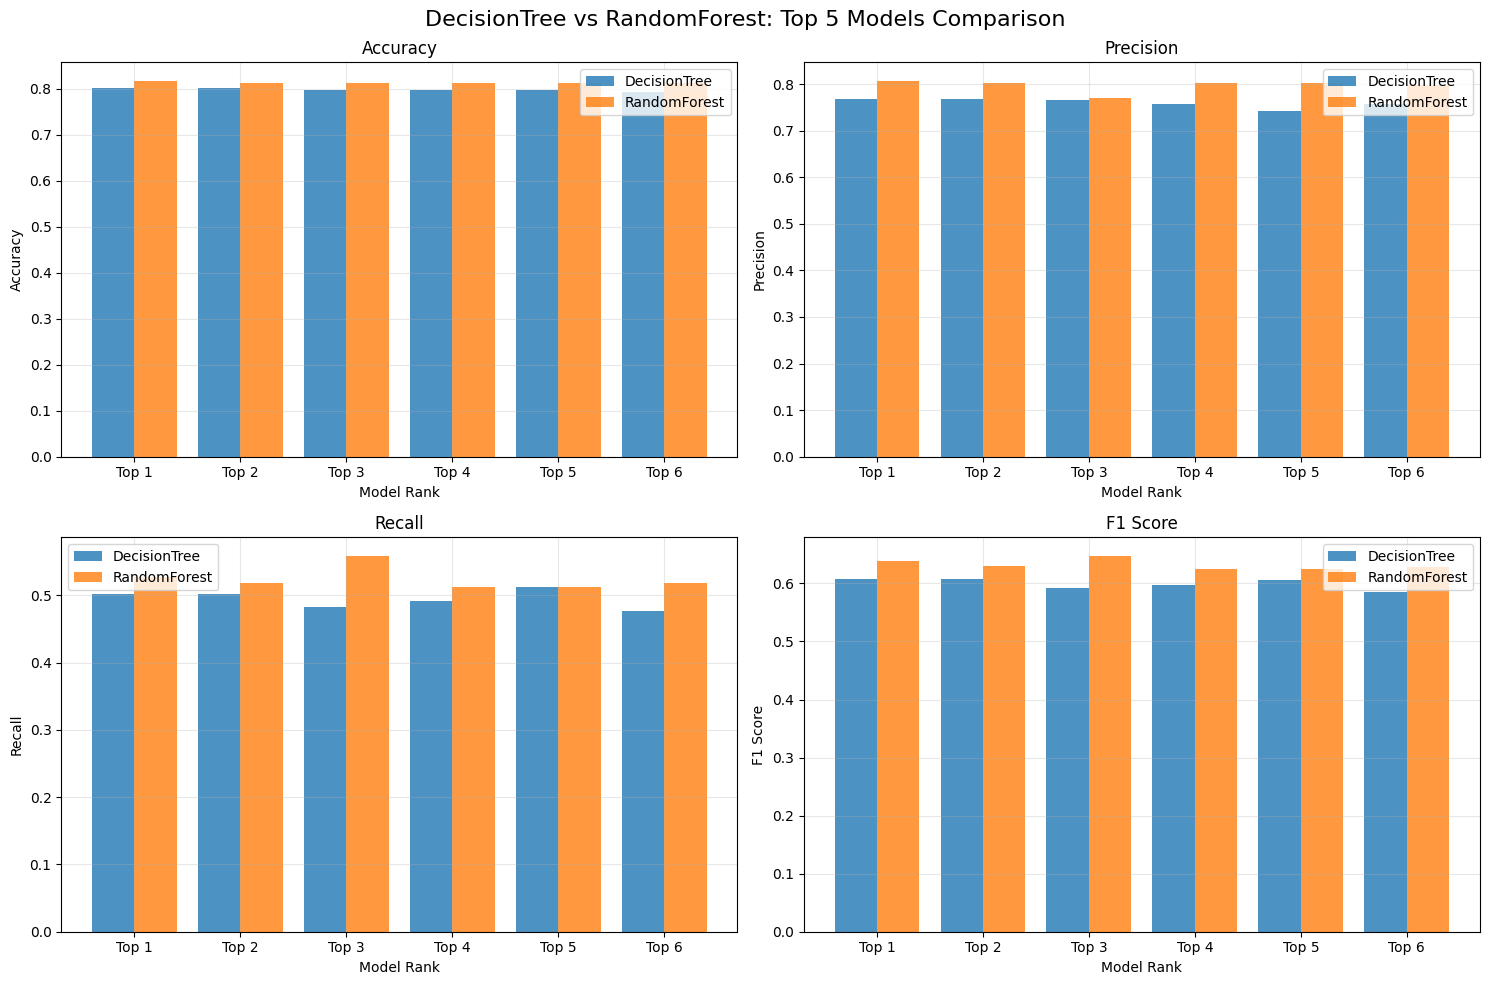

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('DecisionTree vs RandomForest: Top 5 Models Comparison', fontsize=16)

metrics = ['accuracy', 'precision', 'recall', 'f1']
titles = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    ax = axes[i//2, i%2]
    
    x = range(6)
    tree_values = best_tree[metric].head(6).values
    forest_values = best_forest[metric].head(6).values
    
    ax.bar([i-0.2 for i in x], tree_values, width=0.4, label='DecisionTree', alpha=0.8)
    ax.bar([i+0.2 for i in x], forest_values, width=0.4, label='RandomForest', alpha=0.8)
    
    ax.set_title(title)
    ax.set_xlabel('Model Rank')
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels(['Top 1', 'Top 2', 'Top 3', 'Top 4', 'Top 5', 'Top 6'])
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Comparing the performance of our top five **DecisionTreeClassifier** and **RandomForestClassifier** models, we can see that the top forest models consistently outperformed the top **DecisionTreeClassifier** models for this classification task. 

**While some ranked models achieved identical scores, RandomForestClassifier was never outperformed**. Although ranking models by placement may seem arbitrary, our **DecisionTreeClassifier** results showed that vastly different hyperparameter configurations can result in identical top scores. Under the right circumstances, adjusting hyperparameters had little to no factor on performance, implying an innate capacity of the model itself. This suggests that once a model has sufficiently learned the underlying relationships, further tuning of these parameters has limited impact on performance (i.e., it has reached performance capacity). As such, ranking remains a valid method of model comparison, as it directly reflects the model's innate capabilities in achieving success. And as shown above, the comparison reinforces that **RandomForestClassifier is never bested in this leaderboard when compared to DecisionTreeClassifier**.

**This suggests that an optimized RandomForestClassifier is the most reliable model for this binary classification problem.** Across hypertuned candidates, even average-case ensemble models consistently outperform single-tree models, and in the worst-case, they achieve equal performance. Based on the probabilistic nature of machine learning, this is valuable evidence as it suggests consistent reliability when introduced to unknown complexities. Despite having only four feature columns and a relatively small dataset, the ensemble approach demonstrates clear advantages and persistent performance gains.

## Final Model Test + Sanity Check
Based on consistent performance across hypertuned candidates, we select **RandomForestClassifier** as our final model. We will now evaluate it on the test set to assess real-world performance.

### Final Model Test

First, we perform our final model test by predicting `features_test`, which has been isolated from the model up to this point. This ensures that test data does not leak into the model during training or validation, giving us blind benchmark opportunity at every stage. The predictions are stored as `test_predictions`.

In [36]:
test_predictions = final_model.predict(features_test)

Next, we'll compare our `test_predictions` to the true `target_test` values, obtaining performance scores for each benchmark metric.

In [37]:
test_accuracy = accuracy_score(target_test, test_predictions)
test_precision = precision_score(target_test, test_predictions)
test_recall = recall_score(target_test, test_predictions)
test_f1 = f1_score(target_test, test_predictions)

We can store our raw metrics into a dictionary `metrics`, then preview the raw values.

In [38]:
metrics = {
    'Accuracy': test_accuracy,
    'Precision': test_precision,
    'Recall': test_recall,
    'F1 Score': test_f1
}
metrics

{'Accuracy': 0.8227060653188181,
 'Precision': 0.7956204379562044,
 'Recall': 0.558974358974359,
 'F1 Score': 0.6566265060240964}

### Final Model Performance Analysis
To visualize our model's test results, we can plot each metric in a bar chart.

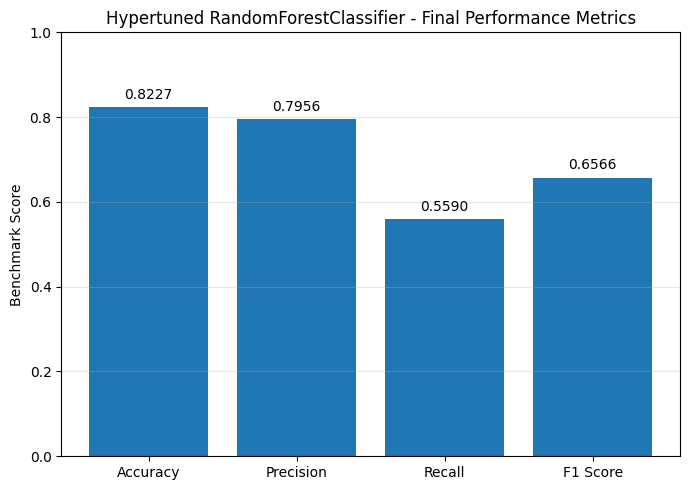

In [39]:
names = list(metrics.keys())
values = list(metrics.values())

plt.figure(figsize=(7, 5))
plt.bar(names, values)

plt.ylim(0, 1)
plt.title('Hypertuned RandomForestClassifier - Final Performance Metrics')
plt.ylabel('Benchmark Score')

# Add value labels on top
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

As a reminder, our validation test resulted in the following metrics:

In [40]:
best_forest.head(1).loc[:, 'accuracy':'f1'].style.format("{:.4f}")

,accuracy,precision,recall,f1
60,0.8165,0.8062,0.5279,0.6380


**As observed, our target metric of accuracy increased to 0.8227, resulting in over 82% accuracy on the test set.** This reinforces our conclusion that the hypertuned RandomForestClassifier is the optimal candidate, demonstrating strong generalization from validation to unseen data.

**While overall accuracy improved, precision slightly decreased.** This indicates that the model classified Smart users as Ultra users slightly more often in testing than in validation, resulting in a small increase in false positives. After splitting the data, we confirmed that the empirical distribution remained consistent at approximately a 70–30 ratio. Given the limited size of the dataset—and therefore the smaller test subset—this variation is expected. As the model is applied to a larger population, these estimates should stabilize. Overall, this minor reduction in precision is acceptable given the improvement in accuracy.

**Recall increased, identifying over 3% more Ultra users than in validation.** Despite the slight increase in false positives, the model demonstrated a stronger ability to capture the minority class. This improvement suggests that the model has developed a more complete understanding of Ultra user behavior while still maintaining strong performance on the majority class.

**The F1 score increased by approximately 2%, maintaining a strong balance between precision and recall.** While precision declined slightly, the larger gain in recall contributed more significantly to the improved balance. This indicates that the model’s performance gains were driven more by improved identification of Ultra users than by misclassification of Smart users. Overall, the model demonstrates well-balanced performance, suggesting effectiveness when used in the prediction of binary classification with equally desired outcomes.

**To visualize the implications on classification, we can observe the Confusion Matrix, which displays the prevalence of True Positives, True Negatives, False Positives, and False Negatives.**

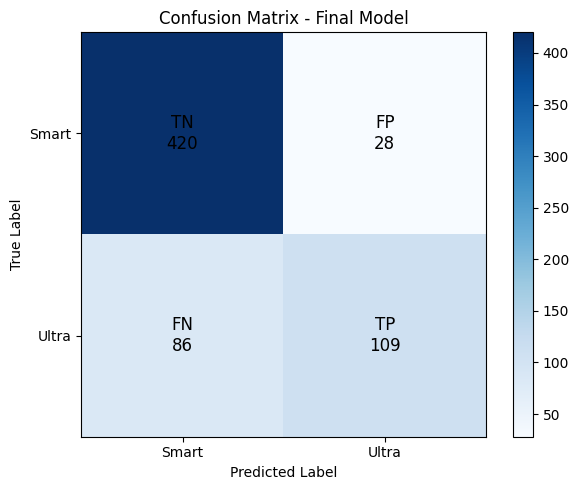

In [41]:
cm = confusion_matrix(target_test, test_predictions)
labels = np.array([
    ['TN', 'FP'],
    ['FN', 'TP']
])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Smart', 'Ultra'])

annot = np.empty_like(cm).astype(str)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot[i, j] = f"{labels[i, j]}\n{cm[i, j]}"

# Plot
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')

plt.xticks([0, 1], ['Smart', 'Ultra'])
plt.yticks([0, 1], ['Smart', 'Ultra'])

# Add text annotations
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, annot[i, j],
                 ha='center', va='center',
                 color='black', fontsize=12)

plt.title('Confusion Matrix - Final Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.colorbar()
plt.grid(False)
plt.show()

**As observed, our prevalence of True Negatives, the identification of Smart users, is the highest.** Ultimately, this is the desired outcome when accuracy is favored. While it is important to recognize Ultra users, our end goal is to correctly identify as many users as possible. This means that high success in the majority is key to a successful campaign.

**Our next most prevalent tile is True Positives, the identification of Ultra users.** This shows that the model is able to identify a meaningful portion of the minority class. This is evident by our increase in recall.

**Most misclassifications are False Negatives, where our model predicts Ultra users to be Smart users.** This shows that our model is more likely to identify an Ultra user as a Smart user, as opposed to predicting a Smart user to be an Ultra user. This suggests that the model has a tendency to under-estimate an Ultra user as opposed to over-estimating a Smart User. This is important contextual evidence to consider, as it suggests the model is conservative in nature.

**False positives are less frequent, showing the high-precision performance rating.** This suggests that when the model predicts that a user is Ultra, there's a strong chance that it is correct. 

### Final Model Feature Importances
We can observe the factors that our model weighed -- and to what extent -- to achieve the results above. This allows us to understand why our model predicted what it did, and ultimately, what defines our market segments.

First, we create a DataFrame using our `features_train_final` training data features and our `final_model` feature importance values.

In [42]:
importance_df = pd.DataFrame({
    'feature': features_train_final.columns,
    'importance': final_model.feature_importances_
}).sort_values(by='importance', ascending=False)

importance_df

,feature,importance
3,mb_used,0.348084
1,minutes,0.254639
0,calls,0.207903
2,messages,0.189374


To better represent this, we will visualize this data in a horizontal bar graph below.

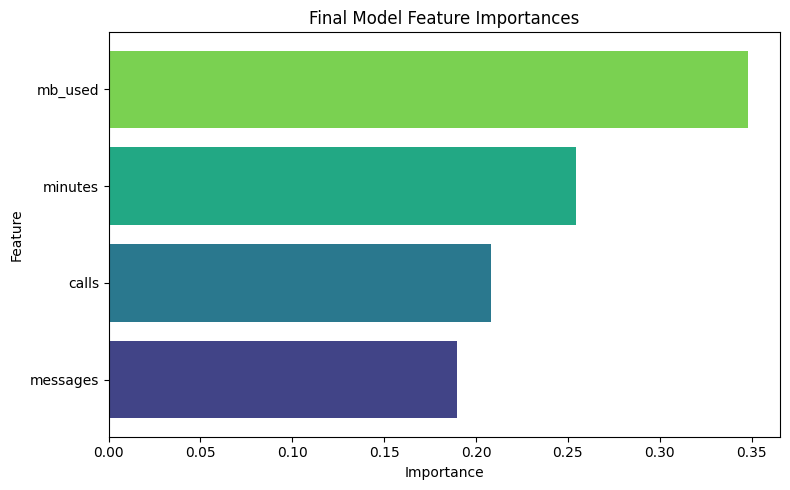

In [43]:
importance_plot_df = importance_df.sort_values(by='importance', ascending=True)

plt.figure(figsize=(8, 5))

colors = plt.cm.viridis(
    np.linspace(0.2, 0.8, len(importance_plot_df))
)

plt.barh(importance_plot_df['feature'],
         importance_plot_df['importance'],
         color=colors)
plt.title('Final Model Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

**As shown above, mb_used is the most influential feature in our final model.** This suggests that overall data consumption is the strongest factor in distinguishing between Smart and Ultra users. This aligns with intuition, as data usage is often one of the clearest indicators of plan fit in modern cellular behavior.

**minutes is the second most important feature, outweighing calls despite their similar relative median increases.** This is an interesting result. While call frequency and total call duration increase at nearly the same rate from Smart to Ultra users, the model places substantially more importance on total call duration. This suggests that how long users stay on the phone is more informative for classification than how often they make calls. Frequency still contributes, but duration appears to provide clearer predictive value.

**messages is the least important feature, but it still carries meaningful weight.** Although it ranks lowest in feature importance, it still contributes substantially to classification and should not be treated as noise. Messaging behavior still helps distinguish between users, especially in cases where more dominant behavioral patterns overlap.

**During Exploratory Data Analysis, we also examined the relative median deltas between Smart and Ultra users.** Comparing those values to our feature importances reveals an interesting contrast. In this model, the ranking of feature importances is nearly the reverse of the ranking of relative median deltas. In other words, the features with the largest proportional differences between groups are not necessarily the most useful for classification.

**See the relative median table below for reference:**

In [44]:
median_table.sort_values(by='delta%', ascending=False)

,smart,ultra,delta,delta%
messages,28.00,38.00,10.00,35.714286
calls,60.00,74.00,14.00,23.333333
minutes,410.56,502.55,91.99,22.405982
mb_used,16506.93,19308.01,2801.08,16.969115


**For example, messages showed the largest relative median increase from Smart to Ultra users, yet the model assigned it the lowest importance.** This suggests that while messaging differs proportionally between groups, it does not provide the clearest decision boundaries for classification. By contrast, mb_used showed the smallest relative median increase, yet it received the highest feature importance. This indicates that data usage provides more reliable thresholds for separating the two classes, even if its proportional difference is smaller.

**A similar pattern appears in voice behavior.** The relative median increases for calls and minutes are nearly identical, yet the model weighs minutes considerably more than calls. This suggests that total call duration is a more useful classification signal than call frequency, even when their group-level differences appear similar in proportional terms.

**Taken together, these results show that proportional difference alone does not determine predictive usefulness.** A feature may show a large relative shift between groups while still overlapping heavily in distribution, making it less effective for classification. Meanwhile, a feature with a smaller proportional difference may still provide cleaner thresholds and stronger separation. This helps explain why the model relied most heavily on `mb_used` and `minutes`, and why performance gains became increasingly incremental as we pushed for higher accuracy. The strongest predictive features were not simply the ones that changed the most between groups, but the ones that separated the groups most effectively.

### Final Model Footnotes

**Model Selection**:
We've determined that a **RandomForestClassifier** with 100 estimators, a max depth of 10, a minimum sample split of 10, a minimum leaf requirement of 1, a max features value of sqrt(num features), and a psuedo-RNG random seed of 42 to be our optimal configuration. This is backed by evidence that supports reliability, consistency, scalability, and even optimal performance in worst-case scenarios compared to competing models. While there where empirical imbalances and overlaps that certainly created resistance, our model performed well above our minimum requirements and even performed better than expected in testing.

**Our results:**
- `Accuracy`: 0.8227060653188181
- `Precision`: 0.7956204379562044
- `Recall`: 0.558974358974359
- `F1 Score`: 0.6566265060240964

**Model Performance**:
We've noted multiple disadvantages that affect our premium minority; however, increased sample size will address many of these issues. By our research, this model shows the greatest promise to scale. It's best-in-class recall posits it as the model with the highest completion of Ultra users, and with its extremely high precision, it shows a fundamental understanding of the Ultra minority. Its record-breaking accuracy should yield the highest possible plan adoption rates, while its record-breaking F1 score makes it an exceptionally well balanced prediction model.

**Auditability Trade-off**:
Per best practices, our initial approach was to first attempt a conservative approach using a single-tree model. Single-tree models can provide a more interpretable result, while ensemble models generally mystify their process more. Interpretability can prove to be beneficial in environments where auditability is desired/required, strict evaluation is needed, or when inferences must be made from the inner process. In our case, auditability and interpretability are not requirements. While auditability of the decision-making process could provide useful marketing insights for consumer modeling, the objective of this case is to expedite the adoption of legacy plans. As such, performance in accuracy takes clear precedence over auditability. Furthermore, exploratory data analysis, empirical distribution inspection, and feature importance showcased that dataset composition is more complex than initially assumed. As it turned out, a single-tree model would not provide the robustness required for this case, as ensemble iterations provided clear, consistent, reliable gains that the single-tree iterations did not capture. As such, the trade-off is well justified.

**Unbiased Outcome Implications**:
As previously mentioned, the dataset size and distribution likely worked against the model's understanding of Ultra users. Aside from their less predictable nature and large overlap with Smart users, they only constitute about 30% of the dataset. This puts them at a statistical and empirical disadvantage as the model has much more Smart user data to train on, and the Smart users are much more predictable in nature. While we could have attempted to balance the dataset with resampling and enforce a 50/50 split (in the spirit of unfavored outcome accuracy), it is a double-edged sword. A real-world sample often yields greater real-world accuracy. Further meddling could cause unintended consequences in bias. Increasing the sample space of Ultra users would mean reducing the sample space of Smart users, giving the model less Smart user data to train on. Smart user predictability could become less reliable, and if our process essentially secured 70% of predictions in a natural distribution by understanding Smart user data, that's not something we'd want to degrade. The use of an ensemble model proved to enhance model understanding of the minority class, allowing us to compensate without disturbing the natural distribution. If the split were more aggressively biased, or if we found that our sample was collected in a biased manner and didn't represent the natural world, we might aim to compensate then. Nevertheless, we took multiple measures to preserve and ensure our unbiased utilization of the data given.